# Домашнее задание 1: персональные рекомендации музыкальных инструментов

**Датасет:** Amazon Review Data (2018), **Musical Instruments, 5-core**.
[Первоисточник и описание полей](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/index.html).
Рекомендуем товары: инструменты, аксессуары и музыкальное оборудование. Отзыв — наблюдаемое
взаимодействие, оценка 4 или 5 — положительный сигнал. Релевантность на validation/test для
**всех** моделей: ещё не известный пользователю товар с будущей оценкой ≥ 4.

Реализованы ItemKNN, iALS, EASE, FM с метаданными и ALS с градуированным таргетом.
Все обучение, scoring, top-10, негативный сэмплинг и метрики реализованы в репозитории.
NumPy/SciPy используются для линейной алгебры; PyTorch — для autograd и Adam внутри FM.

## Загрузка и запуск

Python 3.13, CPU; точные версии — в `requirements.txt`. Из корня репозитория:
```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
python scripts/run_notebook.py
```
Либо открыть `experiments.ipynb` и выполнить **Restart Kernel and Run All**.
Первая загрузка автоматически скачивает **два gzip-архива с сервера UCSD** в `cache/raw/`.
SHA256 сверяются с закреплёнными значениями в коде; данные и модели в GitHub не входят.
Ноутбук каждый раз заново обучает модели; готовые метрики из `results/` для вычислений не читает.
Оценка EASE требует квадратичной памяти: ориентир 16 ГБ RAM. Точное время зависит от CPU/BLAS.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'
os.environ['VECLIB_MAXIMUM_THREADS'] = '2'
import json, random, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from threadpoolctl import threadpool_limits, threadpool_info
from IPython.display import display, Markdown
from recsys.data import load_data, build_protocol
from recsys.experiment import select_hyperparameters, final_comparison, save_results
from models.item_knn import ItemKNN
from models.ials import IALS
from models.ease import EASE
from models.fm import FM
from models.custom_als import CustomALS

CONFIG = json.loads(Path('config.json').read_text())
SEED = CONFIG['seed']
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(CONFIG['threads'])
torch.use_deterministic_algorithms(True)
THREAD_LIMIT = threadpool_limits(limits=CONFIG['threads'])
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'figure.figsize': (10, 4)})
print('Python:', platform.python_version(), '| PyTorch:', torch.__version__, '| seed:', SEED)
display(pd.DataFrame(threadpool_info())[['internal_api', 'num_threads', 'version']])

Python: 3.13.2 | PyTorch: 2.14.1 | seed: 42


,internal_api,num_threads,version
0,openmp,2,None


## 1. Данные и смысл полей

Источник: Jianmo Ni, Jiacheng Li, Julian McAuley, *Justifying recommendations using
distantly-labeled reviews and fine-grained aspects*, EMNLP 2019.
На странице источника выбираются **Musical Instruments / 5-core** и соответствующий файл **metadata**.
Полная категория у источника содержит 1 512 530 отзывов; используемый авторский 5-core — 231 392.
5-core сформирован авторами: каждый пользователь и товар имел не менее пяти отзывов до нашей очистки.
Не делаем дополнительную случайную подвыборку и не отбираем популярные товары по test.

| Исходное поле | Использование |
|---|---|
| `reviewerID`, `asin` | ID пользователя и товара |
| `overall` | Оценка 1…5; обучение и общий критерий релевантности |
| `unixReviewTime` | Дата отзыва, глобальное временное разбиение |
| `title`, `category` из metadata | Название и категории товара, признаки FM |
| `brand` | Анализ полноты метаданных, в FM не включён |

Не используем будущий текст отзыва, `vote`, текущие цены, sales rank или графы `also_buy`.
Ни оценка, ни дата будущего отзыва не подаются в FM при рекомендации.

In [2]:
reviews, metadata, data_audit = load_data('cache')
assert 100_000 <= len(reviews) <= 2_000_000
assert reviews.user_id.nunique() >= 1_000 and reviews.item_id.nunique() >= 1_000
display(pd.DataFrame([
    {'stage': 'source reviews', 'interactions': data_audit['raw_rows']},
    {'stage': 'invalid rows removed', 'interactions': data_audit['invalid_rows']},
    {'stage': 'duplicate user-item rows removed', 'interactions': data_audit['duplicate_user_item_rows']},
    {'stage': 'clean unique interactions', 'interactions': len(reviews)},
]))
display(pd.Series({k: data_audit[k] for k in ['n_users', 'n_items', 'metadata_source_rows',
    'metadata_matched_items', 'metadata_missing_items']}).to_frame('value'))
display(pd.DataFrame(data_audit['files']).T)
print('Period:', pd.to_datetime(reviews.timestamp.min(), unit='s', utc=True), '—',
      pd.to_datetime(reviews.timestamp.max(), unit='s', utc=True))

,stage,interactions
0,source reviews,231392
1,invalid rows removed,0
2,duplicate user-item rows removed,12236
3,clean unique interactions,219156


,value
n_users,27530
n_items,10620
metadata_source_rows,120310
metadata_matched_items,10611
metadata_missing_items,9


,url,sha256,bytes
Musical_Instruments_5.json.gz,https://mcauleylab.ucsd.edu/public_datasets/da...,e3ae8a3f0d70bf63242a49539a8847d30216a3aa2938c0...,39353085
meta_Musical_Instruments.json.gz,https://mcauleylab.ucsd.edu/public_datasets/da...,8e3f0dbe4c6c1aa5b32d350aa26072232beb6160ff3c5d...,173201671


Period: 2003-10-28 00:00:00+00:00 — 2018-09-28 00:00:00+00:00


## 2. EDA и подготовка

Удаляем строки без ID, даты или корректной оценки 1…5. Повторные отзывы на одну пару
user–item заменяем **самым ранним**: поздний отзыв не переписывает обучающий таргет задним числом.
При совпадении даты сохраняем первую строку исходного файла. Это также запрещает попадание
одного товара пользователя в несколько частей. Пропуски метаданных не удаляют взаимодействия:
FM получает отдельный missing-токен. После дедупликации строгий 5-core может нарушиться;
повторный k-core по всей истории не строим, чтобы не усиливать зависимость отбора от будущего.

,missing review fields
user_id,0
item_id,0
rating,0
timestamp,0


,count
malformed_rows,0
invalid_rows,0
malformed_metadata_rows,0
missing_title_items,0
missing_category_items,281
missing_brand_items,86


,user activity,item popularity
count,27530.000000,10620.000000
mean,7.960625,20.636158
std,5.890834,58.183222
min,1.000000,1.000000
25%,5.000000,6.000000
50%,6.000000,9.000000
75%,9.000000,18.000000
max,229.000000,1756.000000


Overall sparsity: 99.92504120%


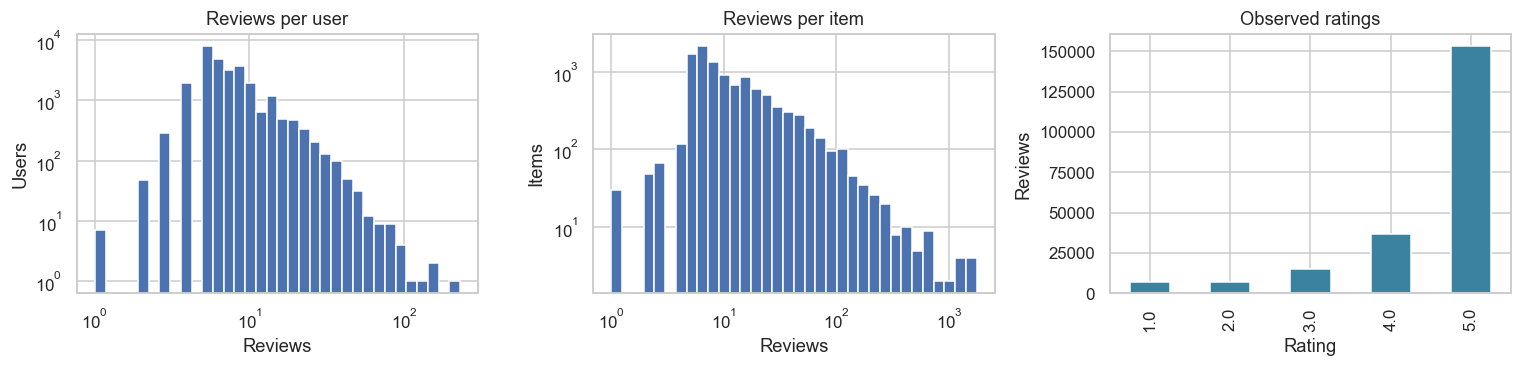

In [3]:
display(pd.Series(data_audit['missing_fields'], name='missing review fields').to_frame())
display(pd.Series({k: data_audit[k] for k in ['malformed_rows', 'invalid_rows',
    'malformed_metadata_rows', 'missing_title_items', 'missing_category_items', 'missing_brand_items']},
    name='count').to_frame())
activity = reviews.groupby('user_id').size()
popularity = reviews.groupby('item_id').size()
display(pd.DataFrame({'user activity': activity.describe(), 'item popularity': popularity.describe()}))
print(f'Overall sparsity: {1 - len(reviews) / (len(activity) * len(popularity)):.8%}')
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].hist(activity, bins=np.geomspace(1, activity.max() + 1, 35))
axes[0].set(xscale='log', yscale='log', title='Reviews per user', xlabel='Reviews', ylabel='Users')
axes[1].hist(popularity, bins=np.geomspace(1, popularity.max() + 1, 35))
axes[1].set(xscale='log', yscale='log', title='Reviews per item', xlabel='Reviews', ylabel='Items')
reviews.rating.value_counts().sort_index().plot.bar(ax=axes[2], color='#3b82a0')
axes[2].set(title='Observed ratings', xlabel='Rating', ylabel='Reviews')
plt.tight_layout(); plt.show()

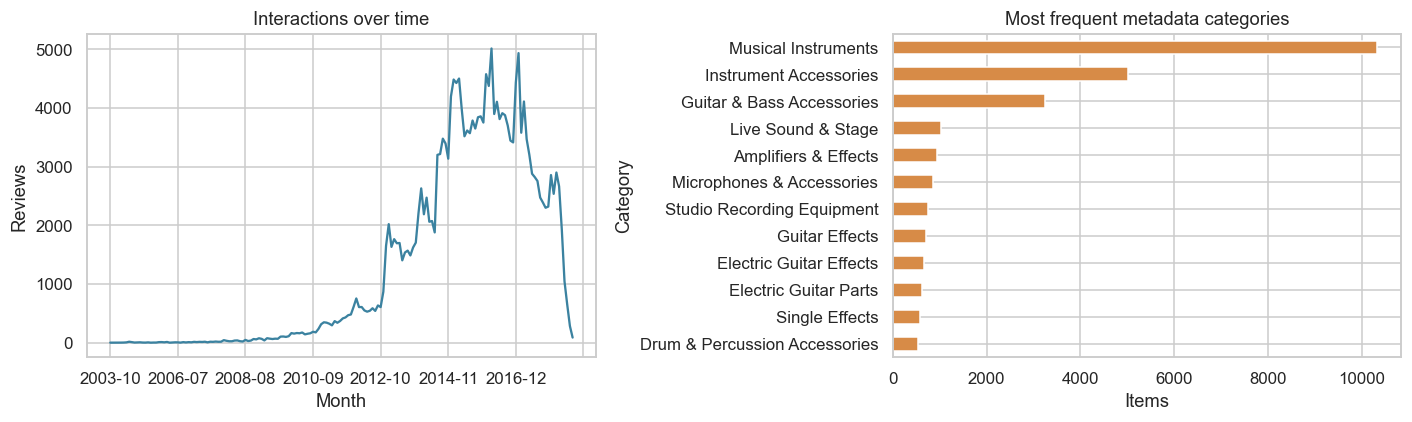

,field,present_items,share_of_clean_items
0,title,10611,0.999153
1,category,10330,0.972693
2,brand,10525,0.991055


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
monthly = reviews.assign(month=pd.to_datetime(reviews.timestamp, unit='s', utc=True).dt.strftime('%Y-%m'))
monthly.groupby('month').size().plot(ax=axes[0], color='#3b82a0')
axes[0].set(title='Interactions over time', xlabel='Month', ylabel='Reviews')
categories = metadata.category.explode().dropna().value_counts().head(12).sort_values()
categories.plot.barh(ax=axes[1], color='#d78b47')
axes[1].set(title='Most frequent metadata categories', xlabel='Items', ylabel='Category')
plt.tight_layout(); plt.show()
display(pd.DataFrame({
    'field': ['title', 'category', 'brand'],
    'present_items': [metadata.title.ne('').sum(), metadata.category.map(len).gt(0).sum(),
                      metadata.brand.ne('').sum()],
    'share_of_clean_items': [metadata.title.ne('').sum()/data_audit['n_items'],
                             metadata.category.map(len).gt(0).sum()/data_audit['n_items'],
                             metadata.brand.ne('').sum()/data_audit['n_items']]
}))

## 3. Протокол оценки и метрики, выбранные до подбора

Основная метрика **NDCG@10**: правильные рекомендации на верхних позициях полезнее.
Вторая метрика **Recall@10**: доля релевантных будущих товаров, найденных в десяти рекомендациях.
Дополнительно показываем HitRate@10 и Coverage@10. Усреднение — по пользователям, а не отзывам.

Для пользователя $u$ с множеством релевантных товаров $R_u$:
$$Recall@10(u)=\frac{|Top10_u\cap R_u|}{|R_u|},\quad
NDCG@10(u)=\frac{\sum_{j=1}^{10}\mathbf1[i_j\in R_u]/\log_2(j+1)}
{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}.$$

Глобальные границы времени — 80-й и 90-й процентили очищенных timestamp, `method='nearest'`.
Все отзывы одной даты находятся с одной стороны границы. Train: $t<t_v$;
validation: $t_v\le t<t_s$; test: $t\ge t_s$. История будущих пользователей не попадает в train.

Словари строим **только по train**, каталог фиксируем для всего эксперимента. Кандидаты — все
товары train за вычетом всей известной истории пользователя. Сэмплирования кандидатов нет.
Новые пользователи/товары вне словарей исключаются из warm-start оценки с отдельным отчётом
о потерях. Пользователь участвует, если у него есть хотя бы один допустимый положительный
товар в соответствующей части; набор пользователей каждой части одинаков для всех моделей.
Validation и test могут включать разные наборы пользователей: это разные временные периоды.

Настройки выбираем исключительно на validation по NDCG@10; при равенстве — первый элемент сетки.
Затем обучаем заново на train+validation с тем же train-каталогом и один раз оцениваем test.
На test исключаем всё известное из train+validation, включая низкие оценки.
Критерий релевантности для пятой модели остаётся `rating >= 4`.

In [5]:
assert CONFIG['k'] == 10 and CONFIG['rating_threshold'] == 4
assert CONFIG['split_quantiles'] == [0.8, 0.9]
protocol = build_protocol(reviews, metadata,
    train_fraction=CONFIG['split_quantiles'][0],
    validation_fraction=CONFIG['split_quantiles'][1]-CONFIG['split_quantiles'][0])
assert protocol.train.timestamp.max() < protocol.validation.timestamp.min()
assert protocol.validation.timestamp.max() < protocol.test.timestamp.min()
assert protocol.val_relevance.multiply(protocol.seen_train).nnz == 0
assert protocol.test_relevance.multiply(protocol.seen_final).nnz == 0
assert 100_000 <= protocol.audit['retained_rows_all_splits'] <= 2_000_000
print('Validation starts:', pd.to_datetime(protocol.audit['validation_cutoff_timestamp'], unit='s', utc=True))
print('Test starts:', pd.to_datetime(protocol.audit['test_cutoff_timestamp'], unit='s', utc=True))
print('Fixed train users/items:', protocol.n_users, protocol.n_items)
print('Train sparsity:', protocol.audit['train_sparsity'])
display(pd.DataFrame(protocol.audit['splits']).T)
print('Max EASE float64 matrix size, GiB:', round(protocol.n_items**2 * 8 / 2**30, 2))

Validation starts: 2017-02-27 00:00:00+00:00
Test starts: 2017-10-01 00:00:00+00:00
Fixed train users/items: 25427 10521
Train sparsity: 0.9993450745404971


,raw_rows,retained_rows,dropped_cold_user_rows,dropped_cold_item_rows,dropped_any_cold_rows,cold_users,cold_items,raw_positive_rows,retained_positive_rows,positive_retention,evaluation_users,users_with_no_eligible_positive,eligible_positive_rows
train,175204.0,175204.0,0.0,0.0,0.0,0.0,0.0,152224.0,152224.0,1.000000,NaN,NaN,NaN
validation,21993.0,15358.0,6448.0,232.0,6635.0,1263.0,78.0,19104.0,13224.0,0.692211,5653.0,584.0,13224.0
test,21959.0,13772.0,7833.0,517.0,8187.0,1460.0,99.0,18715.0,11570.0,0.618221,5102.0,618.0,11570.0


Max EASE float64 matrix size, GiB: 0.82


## 4. Пять моделей и основные формулы

Пусть $O$ — наблюдаемые отзывы, $r_{ui}\in\{1,\ldots,5\}$,
$A_{ui}=\mathbf1[(u,i)\in O\land r_{ui}\ge4]$. Неизвестное взаимодействие не означает
наблюдаемый негатив, но в iALS служит слабым нулевым сигналом.

### ItemKNN — `models/item_knn.py`

Бинарная item-based коллаборативная фильтрация. $n_{ij}=\sum_u A_{ui}A_{uj}$,
$n_i=\sum_u A_{ui}$. Сходство — cosine с подавлением ненадёжных совпадений:
$$s_{ij}=\frac{n_{ij}}{\sqrt{n_i n_j}}\frac{n_{ij}}{n_{ij}+\gamma},\quad s_{ii}=0.$$
Оставляем $L$ лучших соседей каждого исходного товара; оценка $\hat R=AS$.
Нулевые сходства и совпадающие scores разрешаются по возрастанию ASIN.

### iALS — `models/ials.py`

Для отзывов $p_{ui}=\mathbf1[r_{ui}\ge4]$, для остальных пар $p_{ui}=0$.
$c_{ui}=1+\alpha\mathbf1[(u,i)\in O]$ — наблюдаемая низкая оценка получает уверенный ноль.
$$\min_{X,Y}\sum_{ui}c_{ui}(p_{ui}-x_u^T y_i)^2+
\lambda(\|X\|_F^2+\|Y\|_F^2).$$
Точное попеременное решение нормальных уравнений:
$$x_u=(Y^TY+\alpha Y_{O_u}^TY_{O_u}+\lambda I)^{-1}
       (1+\alpha)Y_{O_u}^Tp_{O_u};$$
для $Y$ симметрично. Инверсию для обновления факторов не вычисляем: решаем SPD-систему.

### EASE — `models/ease.py`

$$\min_B\|A-AB\|_F^2+\lambda\|B\|_F^2,\quad diag(B)=0;\quad
P=(A^TA+\lambda I)^{-1},\quad B_{ij}=-P_{ij}/P_{jj},\ B_{jj}=0.$$
Scoring $\hat R=AB$. Реализовано через Cholesky; ограничение нулевой диагонали запрещает
тривиальное копирование входа. Память $O(|I|^2)$, разложение $O(|I|^3)$.

### FM с метаданными — `models/fm.py`

Признаки: one-hot user ID, one-hot item ID, категории и слова названия товара.
Категории передают тип/назначение оборудования; названия — тип, производителя и совместимость.
Для каждого из двух полей: до 16 различных токенов, стабильный SHA256 hashing в 512 отдельных
корзин; веса нормированы так, чтобы квадрат нормы поля был равен 1. Отсутствие — missing-токен.
Категории и названия считаем статическими свойствами карточки, известными при размещении товара.
Словари user/item обучены на train; хеширование не обучается на validation/test.
$$f(z)=w^Tz+\frac12\sum_f[(\sum_jv_{jf}z_j)^2-\sum_jv_{jf}^2z_j^2].$$
Сами поля не добавляются как независимый обучаемый алгоритм: реализована полная FM второго
порядка. Обучение BPR: $\sum_{(u,i^+,i^-)}softplus[-(f(u,i^+)-f(u,i^-))]$ с L2.
Положительные — известные оценки ≥4; по одному равномерному неизвестному негативу на положительный
за эпоху, исключая **все** наблюдаемые отзывы. Сэмплер видит только обучающую историю своей фазы.
Adam из PyTorch обновляет вручную заданную FM; число эпох выбирается по validation.

### CustomALS — `models/custom_als.py`

Разработанный таргет — степень удовлетворённости:
$$p^*_{ui}=\begin{cases}\max(0,(r_{ui}-2)/3),&(u,i)\in O;\\0,&\text{иначе}.\end{cases}$$
Таким образом, оценки 1/2/3/4/5 переходят в 0/0/⅓/⅔/1 вместо 0/0/0/1/1.
Предположение: нейтральный отзыв содержит слабый интерес; 5 сильнее 4.
Меняется **целевая переменная**, включая вклад 3-звёздочных отзывов в правую часть системы.
Матрица confidence, регуляризация и алгоритм совпадают с iALS; левая часть нормальных
уравнений остаётся той же при фиксированном $Y$. Это не перенастройка confidence.
Проверим гипотезу на общем бинарном test, а не на собственном градуированном критерии.

Для причинной интерпретации проводим два заранее заданных контроля: FM без метаданных с
настройками выбранной FM и CustomALS с настройками выбранного базового iALS. Эти настройки
также замораживаются до test. Если сетки выбрали одинаковые настройки iALS/CustomALS,
основная строка CustomALS одновременно является контролем.

In [6]:
print('Primary selection metric:', CONFIG['primary_metric'])
print('Fixed seed:', CONFIG['seed'], '| K:', CONFIG['k'])
display(pd.DataFrame([
    {'model': name, 'trial': j, **params}
    for name, grid in CONFIG['search'].items() for j, params in enumerate(grid)
]).fillna('—'))

Primary selection metric: NDCG@10
Fixed seed: 42 | K: 10


,model,trial,n_neighbors,shrink,n_factors,reg,alpha,n_iters,lr,epochs
0,ItemKNN,0,50.0,10.0,—,—,—,—,—,—
1,ItemKNN,1,150.0,30.0,—,—,—,—,—,—
2,IALS,0,—,—,32.0,1.0,20.0,10.0,—,—
3,IALS,1,—,—,32.0,10.0,20.0,10.0,—,—
4,EASE,0,—,—,—,100.0,—,—,—,—
5,EASE,1,—,—,—,500.0,—,—,—,—
6,FM,0,—,—,32.0,0.00001,—,—,0.01,10.0
7,FM,1,—,—,32.0,0.0001,—,—,0.005,15.0
8,CustomALS,0,—,—,32.0,1.0,20.0,10.0,—,—
9,CustomALS,1,—,—,32.0,10.0,20.0,10.0,—,—


Ограниченная вычислительная сетка задана в `config.json` до обращения к test.
Для каждого из пяти методов проверяем два варианта. У iALS и CustomALS одинаковые сетки,
факторы, число итераций, confidence и seed. Для FM фиксированы batch=2048 и 512 hash bins
на поле, сравниваются learning rate, L2 и число эпох. GPU не используется.
Результаты ниже получены обучением в этой ячейке.

In [7]:
validation_results, selected = select_hyperparameters(protocol, CONFIG)
display(validation_results.sort_values(['model', 'NDCG@10'], ascending=[True, False]))
display(pd.DataFrame([{'model': name, **params} for name, params in selected.items()]).fillna('—'))
Path('results').mkdir(exist_ok=True)
Path('results/selected.json').write_text(json.dumps(selected, indent=2) + '\n')

validation ItemKNN 1/2: NDCG@10=0.019053; fit=0.1s


validation ItemKNN 2/2: NDCG@10=0.020132; fit=0.2s


validation IALS 1/2: NDCG@10=0.018388; fit=7.4s


validation IALS 2/2: NDCG@10=0.018875; fit=7.0s


validation EASE 1/2: NDCG@10=0.017875; fit=9.4s


...

validation CustomALS 1/2: NDCG@10=0.019864; fit=7.7s


validation CustomALS 2/2: NDCG@10=0.020245; fit=7.6s


,model,trial,params,fit_seconds,NDCG@10,Recall@10,HitRate@10,Precision@10,Coverage@10,n_users
9,CustomALS,1,"{""alpha"": 20.0, ""n_factors"": 32, ""n_iters"": 10...",7.635085,0.020245,0.031317,0.060499,0.007642,0.062922,5653
8,CustomALS,0,"{""alpha"": 20.0, ""n_factors"": 32, ""n_iters"": 10...",7.697913,0.019864,0.031193,0.061030,0.007607,0.065963,5653
5,EASE,1,"{""reg"": 500.0}",13.090603,0.019502,0.032409,0.063860,0.007129,0.488167,5653
4,EASE,0,"{""reg"": 100.0}",9.403703,0.017875,0.029356,0.058907,0.006368,0.495010,5653
6,FM,0,"{""epochs"": 10, ""lr"": 0.01, ""n_factors"": 32, ""r...",7.558893,0.019690,0.027516,0.055900,0.010172,0.036498,5653
7,FM,1,"{""epochs"": 15, ""lr"": 0.005, ""n_factors"": 32, ""...",9.358817,0.018239,0.025813,0.053423,0.010295,0.006368,5653
3,IALS,1,"{""alpha"": 20.0, ""n_factors"": 32, ""n_iters"": 10...",7.048443,0.018875,0.029734,0.058907,0.007412,0.062732,5653
2,IALS,0,"{""alpha"": 20.0, ""n_factors"": 32, ""n_iters"": 10...",7.405686,0.018388,0.028176,0.056076,0.006934,0.065963,5653
1,ItemKNN,1,"{""n_neighbors"": 150, ""shrink"": 30}",0.179286,0.020132,0.030102,0.055192,0.007907,0.724456,5653
0,ItemKNN,0,"{""n_neighbors"": 50, ""shrink"": 10}",0.148128,0.019053,0.028811,0.052008,0.007377,0.744511,5653


,model,n_neighbors,shrink,n_factors,reg,alpha,n_iters,lr,epochs
0,ItemKNN,150.0,30.0,—,—,—,—,—,—
1,IALS,—,—,32.0,10.0,20.0,10.0,—,—
2,EASE,—,—,—,500.0,—,—,—,—
3,FM,—,—,32.0,0.00001,—,—,0.01,10.0
4,CustomALS,—,—,32.0,10.0,20.0,10.0,—,—


374

## 5. Финальное сравнение на test

Следующая ячейка заново обучает выбранные конфигурации на train+validation. Все модели
получают одинаковые test-пользователей, кандидатов и историю для исключения. После просмотра
test сетка и признаки не меняются. Время обучения приведено отдельно от времени оценки;
это однократное измерение, а не аппаратно-независимый benchmark.

In [8]:
test_results, controls, example_recommendations, learning_curves = final_comparison(protocol, selected, CONFIG)
main_names = list(CONFIG['search'])
main_results = test_results[test_results.model.isin(main_names)].copy()
comparison = main_results.merge(
    validation_results.sort_values('NDCG@10', ascending=False).drop_duplicates('model')[['model', 'NDCG@10']],
    on='model', suffixes=('', '_validation'))
display(comparison.sort_values('NDCG@10', ascending=False)[[
    'model', 'NDCG@10_validation', 'NDCG@10', 'Recall@10', 'HitRate@10', 'Coverage@10',
    'fit_seconds', 'eval_seconds', 'n_users', 'params']])
save_results(validation_results, selected, test_results, controls, data_audit, protocol, CONFIG, learning_curves)

test ItemKNN: NDCG@10=0.014262; fit=0.2s


test IALS: NDCG@10=0.017577; fit=7.5s


test EASE: NDCG@10=0.015088; fit=9.0s


test FM: NDCG@10=0.014835; fit=6.9s


test CustomALS: NDCG@10=0.017454; fit=7.7s


test FM IDs only: NDCG@10=0.014859; fit=1.9s


,model,NDCG@10_validation,NDCG@10,Recall@10,HitRate@10,Coverage@10,fit_seconds,eval_seconds,n_users,params
1,IALS,0.018875,0.017577,0.028193,0.056644,0.062542,7.471747,0.663864,5102,"{""alpha"": 20.0, ""n_factors"": 32, ""n_iters"": 10..."
4,CustomALS,0.020245,0.017454,0.028785,0.058016,0.061686,7.725179,0.666273,5102,"{""alpha"": 20.0, ""n_factors"": 32, ""n_iters"": 10..."
2,EASE,0.019502,0.015088,0.024975,0.049000,0.392928,9.014817,16.587669,5102,"{""reg"": 500.0}"
3,FM,0.019690,0.014835,0.021083,0.047628,0.031461,6.851211,0.715087,5102,"{""epochs"": 10, ""lr"": 0.01, ""n_factors"": 32, ""r..."
0,ItemKNN,0.020132,0.014262,0.022453,0.042140,0.654976,0.225896,0.499838,5102,"{""n_neighbors"": 150, ""shrink"": 30}"


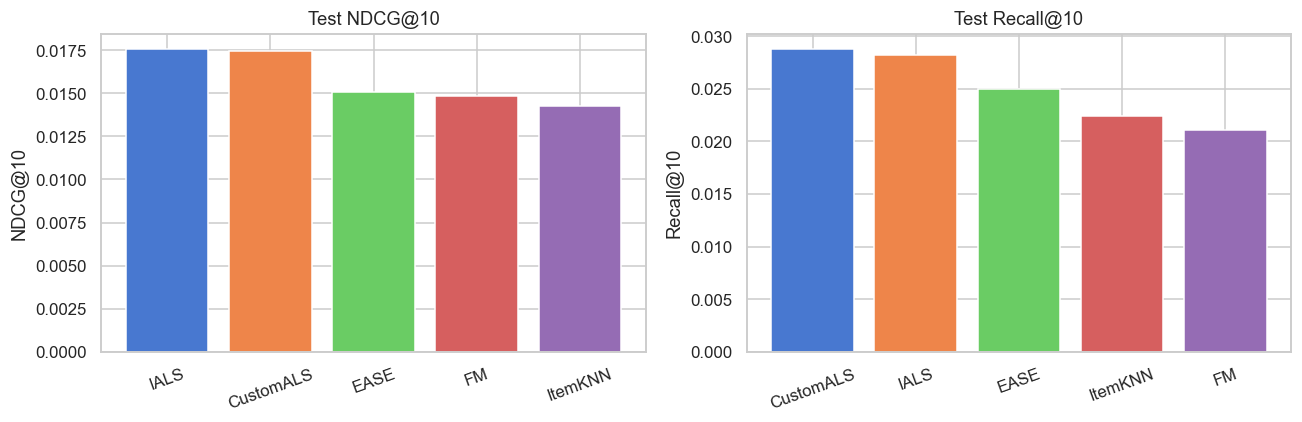

,model,NDCG@10,Recall@10,Coverage@10,params
0,ItemKNN,0.014262,0.022453,0.654976,"{""n_neighbors"": 150, ""shrink"": 30}"
1,IALS,0.017577,0.028193,0.062542,"{""alpha"": 20.0, ""n_factors"": 32, ""n_iters"": 10..."
2,EASE,0.015088,0.024975,0.392928,"{""reg"": 500.0}"
3,FM,0.014835,0.021083,0.031461,"{""epochs"": 10, ""lr"": 0.01, ""n_factors"": 32, ""r..."
4,CustomALS,0.017454,0.028785,0.061686,"{""alpha"": 20.0, ""n_factors"": 32, ""n_iters"": 10..."
5,FM IDs only,0.014859,0.025623,0.022621,"{""epochs"": 10, ""lr"": 0.01, ""n_factors"": 32, ""r..."


,comparison,metric,difference,ci_low,ci_high,n_resamples
0,graded target - binary target,NDCG@10,-0.000124,-0.001241,0.000948,2000
1,graded target - binary target,Recall@10,0.000592,-0.001447,0.002692,2000
2,metadata - IDs only,NDCG@10,-0.000024,-0.002347,0.002219,2000
3,metadata - IDs only,Recall@10,-0.004540,-0.008277,-0.000949,2000


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['NDCG@10', 'Recall@10']):
    frame = main_results.sort_values(metric, ascending=False)
    ax.bar(frame.model, frame[metric], color=sns.color_palette('muted', len(frame)))
    ax.set(title=f'Test {metric}', ylabel=metric)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()
display(test_results[['model', 'NDCG@10', 'Recall@10', 'Coverage@10', 'params']])
display(controls[['comparison', 'metric', 'difference', 'ci_low', 'ci_high', 'n_resamples']])

Для контрольных сравнений выше показан **парный bootstrap по одним и тем же пользователям**:
2 000 повторных выборок с возвращением, seed=42, процентильный 95% интервал среднего изменения.
Интервал относится к вариативности пользователей при фиксированном обучении; он не учитывает
все возможные случайные инициализации и не является доказательством причинности.

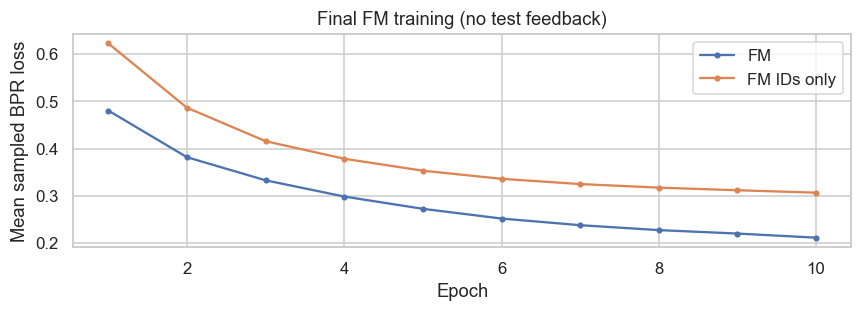

model,CustomALS,EASE,FM,IALS,ItemKNN
rank,,,,,
1,"Ernie Ball Not Even Slinky Nickel Wound Set, ....",CBI MLC LowZ XLR Male to XLR Female Microphone...,D'Addario EXL150H Nickel Wound Electric Guitar...,"Ernie Ball Not Even Slinky Nickel Wound Set, ....","Bigsby B5 Vibrato Tailpiece, Gibson Style Soli..."
2,Fender 250L Nickel Plated Steel Electric Guita...,DAddario Accessories Pro-Winder Guitar String ...,"Snark SN-5 Tuner for Guitar, Bass and Violin (...",Ernie Ball Earthwood Rock and Blues 80/20 Bron...,CBI MLC LowZ XLR Male to XLR Female Microphone...
3,"Graph Tech TUSQ XL 1/4"" Epiphone Slotted Nut","Snark SN-5 Tuner for Guitar, Bass and Violin (...",D'Addario EXL120+ Nickel Wound Electric Guitar...,"Graph Tech TUSQ XL 1/4"" Epiphone Slotted Nut",DAddario Accessories Pro-Winder Guitar String ...
4,Dunlop 44P73 .73mm Nylon Standard Guitar Picks...,Fender Locking Tuners - Polished Chrome,DAddario Accessories Pro-Winder Guitar String ...,Dunlop 44P73 .73mm Nylon Standard Guitar Picks...,Fingerboard Guards - Set of 2
5,Ernie Ball Earthwood Rock and Blues 80/20 Bron...,JOYO JF-37 Bundle Acoustic Guitar Knob,Planet Waves PW-CGTP-305 Classic Series Instru...,Fender 250L Nickel Plated Steel Electric Guita...,Ernie Ball Expression Series Ambient Delay (6184)
6,Guitar Hanger Hook Holder Wall Mount Display -...,Planet Waves PW-CGTP-305 Classic Series Instru...,D'Addario EJ21 Nickel Wound Electric Guitar St...,Fender Pickguard Screws,D'Addario EXL120-7 Nickel Wound 7-String Elect...
7,Planet Waves PW-CGTP-305 Classic Series Instru...,Hosa GTR-205 Straight to Straight Guitar Cable...,D'Addario EXL120-7 Nickel Wound 7-String Elect...,Fender F Neckplate Chrome,D'Addario EXL120+ Nickel Wound Electric Guitar...
8,Fender Pickguard Screws,"Ernie Ball Not Even Slinky Nickel Wound Set, ....",Fender Performance Series Microphone Cable for...,"Musician's Gear Electric, Acoustic and Bass Gu...",D'Addario EJ21 Nickel Wound Electric Guitar St...
9,"Musician's Gear Electric, Acoustic and Bass Gu...",Fingerboard Guards - Set of 2,Snark SN-8 Super Tight All Instrument Tuner,Planet Waves PW-CGTP-305 Classic Series Instru...,D'Addario EXL150H Nickel Wound Electric Guitar...


Example uses first eligible encoded test user; titles come from public item metadata.


In [10]:
fig, ax = plt.subplots(figsize=(8, 3))
for name, values in learning_curves.items():
    ax.plot(np.arange(1, len(values)+1), values, marker='.', label=name)
ax.set(xlabel='Epoch', ylabel='Mean sampled BPR loss', title='Final FM training (no test feedback)')
ax.legend(); plt.tight_layout(); plt.show()
display(example_recommendations[example_recommendations.model.isin(main_names)].pivot(
    index='rank', columns='model', values='title'))
print('Example uses first eligible encoded test user; titles come from public item metadata.')

## 6. Выводы по полученным результатам

In [11]:
best = main_results.sort_values('NDCG@10', ascending=False).iloc[0]
best_recall = main_results.sort_values('Recall@10', ascending=False).iloc[0]
display(Markdown(f'**Лучшая NDCG@10: {best["model"]} — {best["NDCG@10"]:.5f}**, '
    f'Recall@10 = {best["Recall@10"]:.5f}. Настройки: `{best["params"]}`. '
    f'Максимальная Recall@10 у {best_recall["model"]}: {best_recall["Recall@10"]:.5f}.'))
for _, row in controls[controls.metric.eq('NDCG@10')].iterrows():
    direction = 'увеличил' if row.difference > 0 else 'снизил' if row.difference < 0 else 'не изменил'
    evidence = ('Интервал включает ноль; устойчивое преимущество не установлено.'
                if row.ci_low <= 0 <= row.ci_high else 'Интервал не включает ноль при фиксированном обучении.')
    display(Markdown(f'**{row["comparison"]}:** контроль {direction} NDCG@10 на '
        f'{row.difference:+.5f}; 95% CI [{row.ci_low:+.5f}, {row.ci_high:+.5f}]. {evidence}'))
display(Markdown('У iALS и CustomALS сопоставлены одинаковые confidence и настройки в контрольной '
    'строке: разность отражает выбранный таргет. У FM отключались только поля категорий и '
    'названий; неизменны разбиения, позитивы, число эпох и протокол негативов. '
    'Смена числа параметров FM означает, что это контроль всей конструкции признаков, '
    'а не изолированный эффект конкретного слова или категории.'))
display(Markdown(f'После очистки осталось **{len(reviews):,}** взаимодействий, '
    f'в warm-start протокол вошло **{protocol.audit["retained_rows_all_splits"]:,}**; '
    f'test содержит **{len(protocol.test_users):,}** оцениваемых пользователей '
    f'и **{protocol.n_items:,}** товаров-кандидатов.'))

**Лучшая NDCG@10: IALS — 0.01758**, Recall@10 = 0.02819. Настройки: `{"alpha": 20.0, "n_factors": 32, "n_iters": 10, "reg": 10.0}`. Максимальная Recall@10 у CustomALS: 0.02878.

**graded target - binary target:** контроль снизил NDCG@10 на -0.00012; 95% CI [-0.00124, +0.00095]. Интервал включает ноль; устойчивое преимущество не установлено.

**metadata - IDs only:** контроль снизил NDCG@10 на -0.00002; 95% CI [-0.00235, +0.00222]. Интервал включает ноль; устойчивое преимущество не установлено.

У iALS и CustomALS сопоставлены одинаковые confidence и настройки в контрольной строке: разность отражает выбранный таргет. У FM отключались только поля категорий и названий; неизменны разбиения, позитивы, число эпох и протокол негативов. Смена числа параметров FM означает, что это контроль всей конструкции признаков, а не изолированный эффект конкретного слова или категории.

После очистки осталось **219,156** взаимодействий, в warm-start протокол вошло **204,334**; test содержит **5,102** оцениваемых пользователей и **10,521** товаров-кандидатов.

В выполненном запуске iALS и CustomALS выбрали $\lambda=10$ при 32 факторах,
$\alpha=20$ и 10 итерациях; EASE — $\lambda=500$; ItemKNN — 150 соседей и shrink=30.
У FM выбран lr=0.01, L2=$10^{-5}$, 10 эпох. Это лучшие настройки **в заданных двухточечных
сетках**, а не глобально оптимальные параметры.

Градуированный таргет увеличил Recall@10 с 0.02819 до 0.02878, но парный 95% интервал
разности [-0.00145, +0.00269] включает ноль. По основной NDCG@10 iALS немного выше;
убедительного преимущества нового таргета в этом эксперименте нет.

У FM добавление категорий и слов названий практически не изменило NDCG@10 (0.01486 → 0.01484),
а Recall@10 снизилось с 0.02562 до 0.02108; 95% интервал разности [-0.00828, -0.00095]
не включает ноль при фиксированном обучении. Полезность метаданных в этой конструкции
не подтверждается. Общие user/item-ID факторы контрольной и основной FM имели одинаковую
инициализацию; дополнительно изменилась ёмкость модели, а не только смысл признаков.

ItemKNN охватил 65.5% каталога, EASE — 39.3%, iALS — 6.3%: улучшение точности здесь
сопровождается меньшим охватом. На validation наилучшая NDCG@10 была у CustomALS (0.02025),
на test — у iALS (0.01758). Это показывает, почему validation и test следует разделять;
по test новые параметры не выбирались. Все числа этого абзаца относятся к сохранённому
запуску с `config.json`, seed=42; динамические таблицы и выводы выше вычисляются заново.

**Ограничения.** Отзыв — запаздывающий и смещённый индикатор потребления: нет экспозиций,
неизвестны покупки без отзывов. Оценки преимущественно высокие; выводы о градуированном
сигнале зависят от этой асимметрии. Преобразование оценок предполагает условно порядковую
шкалу и конкретное расстояние между уровнями, что требует отдельной проверки на других данных.

Готовый 5-core выбирался авторами по всей истории и исключает редких пользователей и товары;
временной split внутри него не устраняет этот selection bias. Результаты относятся к
warm-start пользователям с будущим позитивным отзывом. Доли исключённых cold-start событий
показаны в таблице протокола; качество на них не измерено. Каталог заморожен на train и
поэтому не оценивает появление новых товаров.

Метаданные — снимок карточек, а не исторический журнал изменений. Название и категория
обычно существуют до отзыва; это принятое здесь допущение доступности контента, но точные
прошлые версии источник не даёт. Запрещённые динамические поля и будущие отзывы не использованы.
Хеширование создаёт коллизии и ограничивает текст первыми 16 токенами.

Использован один seed и небольшая заранее заданная сетка; различия нельзя обобщать на
любые настройки этих семейств. Bootstrap не отражает вариативность обучения по seed.
EASE требует $O(|I|^2)$ памяти. Для production также нужны оценка cold-start, экспозиций,
разнообразия, доверительных интервалов по повторным обучениям и онлайн-проверка.

Агрегированные результаты, выбранные параметры, SHA256, версии библиотек и полный аудит
сохраняются в `results/`. Проверки формул, исключения известных товаров, временного
разбиения, метрик и FM находятся в `tests/`; запуск: `python -m pytest -q`.